## 认证与鉴权（JWT + OAuth2 + RBAC）

### 一、认证与鉴权


| 英文	          | 中文          | 	回答的问题        |	失败返回|
|--------------|-------------|---------------|---|
| Authentication | 	认证 / 身份验证	 | 你是谁？	         |401 Unauthorized	|
| Authorization	 | 授权 / 鉴权	    | 你能干什么？	       |403 Forbidden|

======================================================

⭐ 401 和 403 的边界（面试高频）：
- 401 = 我不知道你是谁（没带 token / token 过期 / 签名错）→ 客户端应该去登录
- 403 = 我知道你是谁，但你没这个权限（普通用户访问管理接口）→ 重新登录也没用

### 二、密码认证
使用 `passlib` + `bcrypt` 安全存储密码，禁止明文存储
```
uv add passlib[bcrypt] passlib[argon2]
```

In [1]:
from passlib.context import CryptContext

from crud.users import get_user_by_username

# 创建加密上下问
pwd_context = CryptContext(schemes=["argon2", "bcrypt"], deprecated="auto")
# 加密
def get_password_hash(password: str) -> str:
    return pwd_context.hash(password)
# 密码校验
def verify_password(plain_password: str, hashed_password: str) -> bool:
    return pwd_context.verify(plain_password, hashed_password)

if __name__ == "__main__":
    hashed_password = get_password_hash("123456xxx")
    res = verify_password("123456xxx", hashed_password)
    print(res)

True


### 三、JWT 认证

理解 JSON Web Token 的签发、携带和验证流程，以及如何使用 `PyJWT` 库进行实现

#### 1. JWT认证流程
- 客户端 → 发送用户名/密码 → POST /auth/login
- 服务端 → 验证凭据 → 签发 JWT（access_token）
- 客户端 → 携带 JWT 请求 → Authorization: Bearer <token>
- 服务端 → 验证 JWT → 提取用户信息 → 处理请求
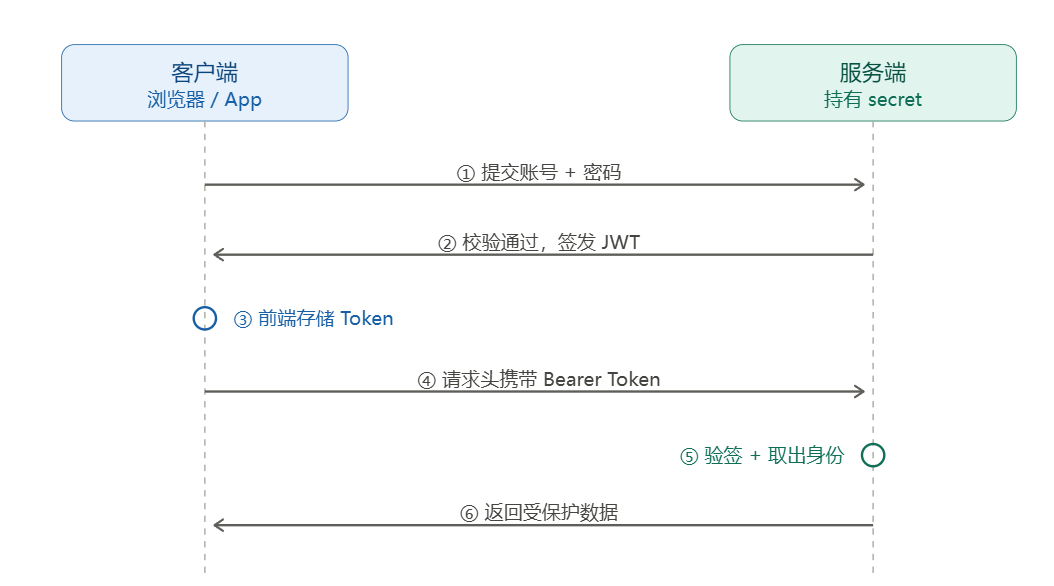

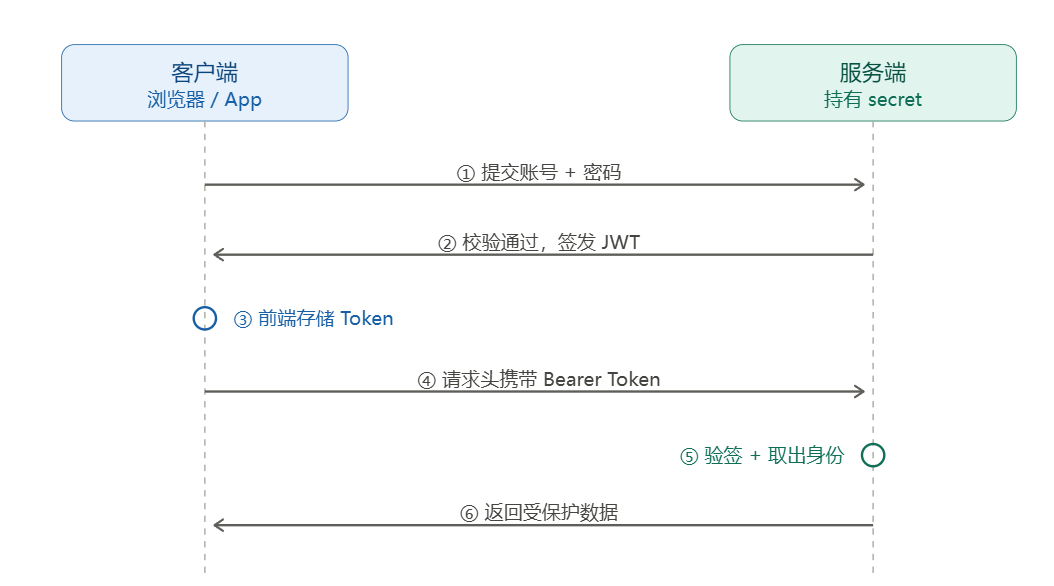

#### 2. JWT 长什么样子

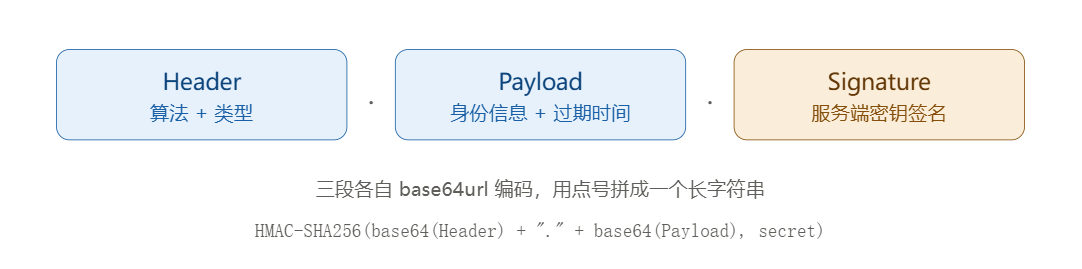

```
第 1 步：拼串
    signing_input = base64url(Header) + "." + base64url(Payload)

第 2 步：算哈希
    HS256  →  raw = HMAC-SHA256(signing_input, secret)
    RS256  →  raw = RSA-SHA256(signing_input, private_key)

第 3 步：编码
    signature = base64url(raw)
```

```
浏览器                          FastAPI
  |                               |
  |-- POST /auth/login ---------->|  ① 查库比对密码
  |                               |  ② 组装 payload → 签名 → 返回
  |<-- {access_token, ...} -------|
  |                               |
  |-- GET /api/me                 |
  |   Authorization: Bearer xxx ->|  ③ 拆三段
  |                               |  ④ 白名单 alg
  |                               |  ⑤ 重算签名比对
  |                               |  ⑥ 校验 exp/iss/aud
  |                               |  ⑦ 查 jti 黑名单
  |                               |  ⑧ 取出 sub 认人（不查库）
  |<-- {user_id, role} -----------|
```

#### 3. JWT 实现
```
uv add pyjwt
```

In [2]:
# 生成 JWT 密钥
import secrets
print(secrets.token_hex(32)) # 生成 64 个十六进制字符 = 32 字节

cd507226224ad25bfdf8e902b33e98fcd02443c56c81e240b28acb59dc4415b3


##### 3.1 签发函数（服务端）
- 客户端：用户输入用户名密码
- 服务器：验证密码正确，返回 JWT Token（access_token）

In [12]:
JWT_SECRET_KEY = "5efb4fd1ef02fa275ca4f8cdbb70d7f4c04672642478e9c461f06f77980a1807"
JWT_ALGORITHM="HS256"
ACCESS_TOKEN_MINUTES=15
REFRESH_TOKEN_DAYS=7

import uuid
from datetime import datetime, timedelta, timezone
import jwt

if len(JWT_SECRET_KEY) < 32:
    raise RuntimeError("JWT_SECRET 太短，HS256 至少需要 32 字节")

# Payload: 真正装业务信息的地方
# 三个 ⭐ 是关键：sub 用字符串、iat 和 exp 用带时区的 datetime、jti 必须唯一
def _base_payload(user_id: str, token_type: str, delta: timedelta) -> dict:
    now = datetime.now(timezone.utc)                # ⭐ UTC，别用 datetime.now() 裸的
    return {
        # 注册声明：规范预定义好名字和含义，不要自己乱用这些名字
        "sub": str(user_id),                        # ⭐ subject, 这个token属于谁（用户id), 必须字符串
        "iat": now,                                 # ⭐ issued at, 签发时间点
        "exp": now + delta,                         # ⭐ expires at, 过期时间点
        "jti": uuid.uuid4().hex,                    # ⭐ jwt id, 唯一 ID，登出时把它扔进黑名单
        "iss": "my-app",                            # ⭐ issuer, 签发人
        "aud": "my-client",                         # ⭐ audience, 受众
        # 自定义声明：业务内部约定，前后端说好就行
        "type": token_type,                         # ⭐ type, 令牌类型, access / refresh
        # ...
    }

def create_access_token(user_id: str, role: str) -> str:
    # 注册声明
    payload = _base_payload(user_id, "access", timedelta(minutes=ACCESS_TOKEN_MINUTES))
    # 私有声明
    payload["role"] = role                          # ⭐ 免查库鉴权就靠它
    return jwt.encode(payload, JWT_SECRET_KEY, algorithm=JWT_ALGORITHM)

def create_refresh_token(user_id: str) -> str:
    payload = _base_payload(user_id, "refresh", timedelta(days=REFRESH_TOKEN_DAYS))
    return jwt.encode(payload, JWT_SECRET_KEY, algorithm=JWT_ALGORITHM)

逐字段解读本例的 Payload
```
{
# 注册声明
  "sub": "1001",                 # ⭐ subject, 这个token属于谁（用户id), 必须字符串
  "iat": 1792828920,             # ⭐ issued at, 签发时间点, 2026-10-24 08:02:00 UTC
  "exp": 1792829820,             # ⭐ expires at, 过期时间点, 2026-10-24 08:17:00 UTC，即签发后 15 分钟
  "jti": "7f3a9c2e4b6d8f01",     # ⭐ jwt id, 令牌的唯一 ID，登出时把它扔进黑名单
  "iss": "my-app",               # ⭐ issuer, 签发方是 my-app 这个服务端
  "aud": "my-client"             # ⭐ audience, 受众是 my-client 这个客户端

# 私有声明
  "name": "zhangsan",
  "role": "admin",               # ⭐ 免查库鉴权
}
```

手工拆解 JWT Token

In [13]:
import base64, json
jwt_token = create_access_token("1001", "admin")
header_seg, payload_seg, sig_seg = jwt_token.split(".")   # ⭐ 按点号切三段
def decode(seg):
    seg += "=" * (-len(seg) % 4)                      # ⭐ 补 padding
    return json.loads(base64.urlsafe_b64decode(seg))

print(decode(header_seg))    # {'alg': 'HS256', 'typ': 'JWT'}
print(decode(payload_seg))   # {'sub': '1001', 'role': 'admin', ...}

{'alg': 'HS256', 'typ': 'JWT'}
{'sub': '1001', 'iat': 1792898943, 'exp': 1792899843, 'jti': '7ed550a53f7a42f4907ba1b88233e615', 'iss': 'my-app', 'aud': 'my-client', 'type': 'access', 'role': 'admin'}


In [14]:
jwt.decode(
    jwt_token,
    JWT_SECRET_KEY,
    algorithms=[JWT_ALGORITHM],
    audience="my-client",
    issuer="my-app"
)

{'sub': '1001',
 'iat': 1792898943,
 'exp': 1792899843,
 'jti': '7ed550a53f7a42f4907ba1b88233e615',
 'iss': 'my-app',
 'aud': 'my-client',
 'type': 'access',
 'role': 'admin'}

##### 3.2 验签函数（服务端）
- 客户端：发送携带 JWT Token 的请求
- 服务器：验证 JWT Token 的正确性，提取用户信息（role）

In [15]:
import jwt
from fastapi import HTTPException, status

def verify_token(token: str, expect_type: str = "access") -> dict:
    try:
        payload = jwt.decode(
            token,
            JWT_SECRET_KEY,
            algorithms=[JWT_ALGORITHM],              # ⭐ 白名单，绝不从 header 读 alg
            audience="my-client",                    # ⭐ 校验 aud
            issuer="my-app",                         # ⭐ 校验 iss
            options={
                "require": ["sub", "iat", "exp"],    # ⭐ 缺字段直接失败，防无过期令牌
                "verify_exp": True,
                "verify_aud": True,
                "verify_iss": True,
            },
        )
    except jwt.ExpiredSignatureError:
        raise HTTPException(status.HTTP_401_UNAUTHORIZED, "令牌已过期")
    except jwt.InvalidTokenError:                # ⭐ 其余所有异常统一 401，别泄露细节
        raise HTTPException(status.HTTP_401_UNAUTHORIZED, "令牌无效")
    if payload.get("type") != expect_type:       # ⭐ 防 refresh token 当 access 用
        raise HTTPException(status.HTTP_401_UNAUTHORIZED, "令牌类型错误")
    return payload

In [16]:
verify_token(jwt_token)

{'sub': '1001',
 'iat': 1792898943,
 'exp': 1792899843,
 'jti': '7ed550a53f7a42f4907ba1b88233e615',
 'iss': 'my-app',
 'aud': 'my-client',
 'type': 'access',
 'role': 'admin'}

### 四、OAuth2

在 FastAPI 里声明 OAuth2 安全方案，配合依赖注入完成登录、取 Token、校验 Token、做权限控制，并自动写进 OpenAPI 文档。
```
from fastapi.security import OAuth2PasswordBearer, OAuth2PasswordRequestForm, SecurityScopes
```
| 类 | 作用 | 典型位置 |
|---|---|---|
| `OAuth2` | OAuth2 安全方案基类 | 通常不直接使用 |
| `OAuth2PasswordBearer` | 从 `Authorization: Bearer <token>` 中取 token | 受保护路由的依赖 |
| `OAuth2PasswordRequestForm` | 解析登录表单 `username`、`password` | 登录接口 |
| `OAuth2PasswordRequestFormStrict` | 严格版登录表单，强制 `grant_type=password` | 需要严格合规时使用 |
| `SecurityScopes` | 声明当前路由需要哪些 scope | 权限校验依赖 |
| `OAuth2AuthorizationCodeBearer` | 授权码流程，适合对接外部 OAuth2 提供方 | 第三方登录/授权 |





#### 4.1. `OAuth2PasswordBearer`：取 Token，不校验 Token


它本质上是一个 依赖项，作用是告诉 FastAPI：
- 客户端应该通过 `Authorization: Bearer <token>` 传 token
- token 从哪里获取，由 `tokenUrl` 指定；
- Swagger UI 的 Authorize 按钮会根据它生成登录入口。

In [17]:
from fastapi import Depends
from fastapi.security import OAuth2PasswordBearer

oauth2_scheme = OAuth2PasswordBearer(tokenUrl="/api/auth/login") # tokenUrl: 只影响文档，不参与任何鉴权逻辑

def get_current_user(token: str = Depends(oauth2_scheme)):
        username: str = verify_token(token).get("sub")
        if username is None:
            raise HTTPException(status.HTTP_401_UNAUTHORIZED, "用户不存在")

        # user = get_user_by_username(users_db, username=username)
        # if user is None:
        #     raise HTTPException(status.HTTP_401_UNAUTHORIZED, "用户不存在")
        # return user

# oauth2_scheme 被 Depends() 调用时，内部做的就是
"""
def oauth2_scheme(request: Request) -> str:
    auth = request.headers.get("Authorization", "")
    if not auth.startswith("Bearer "):                 # ⭐ 前缀必须是 Bearer 加一个空格
        raise HTTPException(401, "Not authenticated",  # ⭐ 缺失或格式错都是这个
                            {"WWW-Authenticate": "Bearer"})
    return auth[7:]                                     # ⭐ 切掉 "Bearer " 这 7 个字符
"""

#### 4.2 `OAuth2PasswordRequestForm`：解析登录表单

登录接口通常用它接收用户名和密码：

In [ ]:
from fastapi import Depends
from fastapi.security import OAuth2PasswordRequestForm
from fastapi import FastAPI
app = FastAPI()
@app.post("/api/auth/login")
def login(form_data: OAuth2PasswordRequestForm = Depends()):
    username = form_data.username
    password = form_data.password
    # TODO: 验证用户名和密码
    token = create_access_token(username, "admin")
    return {"access_token": token, "token_type": "bearer"}

它接收的是 表单数据，不是 JSON。也就是说前端调用时通常要用 application/x-www-form-urlencoded，字段名必须是 username 和 password

返回格式一般要符合 OAuth2 习惯：
```
return {
    "access_token": token,
    "token_type": "bearer",
}
```

#### 4.3 `SecurityScopes`：做细粒度权限控制


如果只是判断“有没有登录”，用 `OAuth2PasswordBearer` + `Depends` 就够了。

如果要判断“有没有某个权限”，就需要 `SecurityScopes`。

In [ ]:
from fastapi import Depends, Security
from fastapi.security import OAuth2PasswordBearer, SecurityScopes

oauth2_scheme = OAuth2PasswordBearer(
    tokenUrl="/api/auth/login",
    scopes={"read": "读取数据", "write": "写入数据"},
)

@app.get("/items")
def list_items(user: dict = Security(get_current_user, scopes=["read"])):
    return user

#### 容易踩坑的点
- `OAuth2PasswordBearer` 只负责取 token，不负责验证 JWT。
- `OAuth2PasswordRequestForm` 是表单依赖，不是 JSON Body。
- tokenUrl 必须和真实登录路由一致，否则 Swagger UI 会调错地址。
- `JWT payload` 不要放密码、身份证等敏感信息，因为它只是编码，不是加密。
- 密码不要明文存储，生产环境建议用 `bcrypt`、`argon2` 等慢哈希算法。